In [ ]:
import os
import cv2
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from tqdm import tqdm
from pathlib import Path
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as F
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.rpn import AnchorGenerator

# SETUP
DATASET_DIR = Path("C:\\Users\\omari\\OneDrive\\Documentos\\MRSI\\2nd\\AIA\\project_1\\dataset")
    
WIDER_TRAIN_DIR = DATASET_DIR / "WIDER_train" / "WIDER_train" / "images"
WIDER_VAL_DIR   = DATASET_DIR / "WIDER_val" / "WIDER_val" / "images"
WIDER_TEST_DIR  = DATASET_DIR / "WIDER_test" / "WIDER_test" / "images"

WIDER_ANNO = DATASET_DIR / "wider_face_split" / "wider_face_split" / "wider_face_train_bbx_gt.txt"
WIDER_VAL_ANNO = DATASET_DIR / "wider_face_split" / "wider_face_split" / "wider_face_val_bbx_gt.txt"


DRIVE_SAVE_DIR = Path(
    r"C:\Users\omari\OneDrive\Documentos\MRSI\2nd\AIA\project_1\AIA_TP1\outputs\vgg16"
)
DRIVE_SAVE_DIR.mkdir(parents=True, exist_ok=True)

# optuna hyperparameters 
OPTIMAL_LR = 2.7641832368009826e-05
OPTIMAL_WEIGHT_DECAY = 9.935449124387662e-05
OPTIMAL_RPN_NMS = 0.5017305625552403

In [2]:
def parse_annotations(anno_path):
    dataset_records = []
    with open(anno_path, 'r') as f:
        lines = f.readlines()

    i = 0
    while i < len(lines):
        img_rel_path = lines[i].strip()
        i += 1
        num_faces = int(lines[i].strip())
        i += 1

        boxes = []
        if num_faces == 0:
            i += 1
        else:
            for _ in range(num_faces):
                parts = lines[i].strip().split()
                x, y, w, h = map(int, parts[:4])
                if w > 0 and h > 0:
                    boxes.append((x, y, w, h))
                i += 1

        dataset_records.append({
            'img_path': img_rel_path,
            'boxes': boxes
        })

    return dataset_records

class WiderFaceTorchDataset(Dataset):
    def __init__(self, records, img_dir, transforms=None):
        self.records = records
        self.img_dir = img_dir
        self.transforms = transforms

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        record = self.records[idx]
        img_path = self.img_dir / record['img_path']

        img = Image.open(img_path).convert("RGB")
        img = F.to_tensor(img)

        boxes = []
        for (x, y, w, h) in record['boxes']:
            if w > 0 and h > 0:
                boxes.append([x, y, x + w, y + h])

        if len(boxes) > 0:
            boxes = torch.as_tensor(boxes, dtype=torch.float32)
            labels = torch.ones((len(boxes),), dtype=torch.int64)
        else:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels
        }

        if self.transforms is not None:
            img, target = self.transforms(img, target)

        return img, target

def collate_fn(batch):
    return tuple(zip(*batch))

In [ ]:
def create_faster_rcnn_vgg16():
    vgg = torchvision.models.vgg16(weights=torchvision.models.VGG16_Weights.DEFAULT)
    backbone = vgg.features
    backbone.out_channels = 512

    anchor_generator = AnchorGenerator(
        sizes=((16, 32, 64, 128, 256),),
        aspect_ratios=((0.5, 1.0, 2.0),)
    )

    roi_pooler = torchvision.ops.MultiScaleRoIAlign(
        featmap_names=['0'],
        output_size=7,
        sampling_ratio=2
    )

    model = FasterRCNN(
        backbone,
        num_classes=2,
        rpn_anchor_generator=anchor_generator,
        box_roi_pool=roi_pooler,
        rpn_nms_thresh=OPTIMAL_RPN_NMS 
    )
    return model

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Versão do PyTorch: {torch.__version__}")
print(f"A treinar no dispositivo: {device}")

records = parse_annotations(WIDER_ANNO)
train_dataset = WiderFaceTorchDataset(records, WIDER_TRAIN_DIR)
train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn
)

val_records = parse_annotations(WIDER_VAL_ANNO)
val_dataset = WiderFaceTorchDataset(val_records, WIDER_VAL_DIR)
val_loader = DataLoader(
    val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

model = create_faster_rcnn_vgg16().to(device)

params = [p for p in model.parameters() if p.requires_grad]
optimizer = torch.optim.Adam(
    params,
    lr=OPTIMAL_LR,
    weight_decay=OPTIMAL_WEIGHT_DECAY
)

num_epochs = 30
scaler = torch.amp.GradScaler('cuda')
best_val_loss = float('inf')

train_loss_history = []
val_loss_history = []

loss_classifier_history = []
loss_box_reg_history = []
loss_objectness_history = []
loss_rpn_box_reg_history = []

early_stopping_patience = 3
epochs_no_improve = 0

Versão do PyTorch: 2.5.1+cu121
A treinar no dispositivo: cuda


In [ ]:
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    epoch_loss_classifier = 0.0
    epoch_loss_box_reg = 0.0
    epoch_loss_objectness = 0.0
    epoch_loss_rpn_box_reg = 0.0

    loop = tqdm(train_loader, desc=f"Época [{epoch + 1}/{num_epochs}] (Treino)", leave=True)

    for step, (images, targets) in enumerate(loop):
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        optimizer.zero_grad()

        with torch.amp.autocast('cuda'):
            loss_dict = model(images, targets)
            losses = sum(loss for loss in loss_dict.values())

        scaler.scale(losses).backward()
        scaler.step(optimizer)
        scaler.update()

        running_loss += losses.item()

        epoch_loss_classifier += loss_dict.get('loss_classifier', torch.tensor(0.0)).item()
        epoch_loss_box_reg += loss_dict.get('loss_box_reg', torch.tensor(0.0)).item()
        epoch_loss_objectness += loss_dict.get('loss_objectness', torch.tensor(0.0)).item()
        epoch_loss_rpn_box_reg += loss_dict.get('loss_rpn_box_reg', torch.tensor(0.0)).item()

        avg_step_loss = running_loss / (step + 1)
        loop.set_postfix(loss_instant=f"{losses.item():.4f}", loss_media=f"{avg_step_loss:.4f}")

    current_train_loss = running_loss / len(train_loader)

    loss_classifier_history.append(epoch_loss_classifier / len(train_loader))
    loss_box_reg_history.append(epoch_loss_box_reg / len(train_loader))
    loss_objectness_history.append(epoch_loss_objectness / len(train_loader))
    loss_rpn_box_reg_history.append(epoch_loss_rpn_box_reg / len(train_loader))

    val_loss_total = 0.0
    model.train()
    with torch.no_grad():
        val_loop = tqdm(val_loader, desc=f"Época [{epoch + 1}/{num_epochs}] (Validação)", leave=False)
        for images, targets in val_loop:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            with torch.amp.autocast('cuda'):
                loss_dict = model(images, targets)
                losses = sum(loss for loss in loss_dict.values())

            val_loss_total += losses.item()

    current_val_loss = val_loss_total / len(val_loader)

    train_loss_history.append(current_train_loss)
    val_loss_history.append(current_val_loss)

    print(f"\n--> Fim da Época [{epoch + 1}/{num_epochs}] | Train Loss: {current_train_loss:.4f} | Val Loss: {current_val_loss:.4f}")

    checkpoint_path = DRIVE_SAVE_DIR / f"faster_rcnn_epoca_{epoch + 1}.pth"
    torch.save(model.state_dict(), checkpoint_path)

    if current_val_loss < best_val_loss:
        best_val_loss = current_val_loss
        best_model_path = DRIVE_SAVE_DIR / 'modelo_best.pt'
        torch.save(model.state_dict(), best_model_path)
        print(f"Novo melhor modelo salvo no Drive! (Val Loss: {best_val_loss:.4f})\n")
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        print(f"Val Loss não melhorou. (Melhor: {best_val_loss:.4f}) | {epochs_no_improve}/{early_stopping_patience} épocas sem melhoria.\n")

        if epochs_no_improve >= early_stopping_patience:
            print(f"Early Stopping ativado! O treino parou após {epoch + 1} épocas.")
            break

print("Treino finalizado com sucesso!")

Época [1/30] (Treino): 100%|██████████| 6440/6440 [54:36<00:00,  1.97it/s, loss_instant=0.0373, loss_media=0.2107]  



--> Fim da Época [1/30] | Train Loss: 0.2107 | Val Loss: 0.1940
Novo melhor modelo salvo no Drive! (Val Loss: 0.1940)



Época [2/30] (Treino): 100%|██████████| 6440/6440 [49:06<00:00,  2.19it/s, loss_instant=0.1103, loss_media=0.1740]  



--> Fim da Época [2/30] | Train Loss: 0.1740 | Val Loss: 0.1618
Novo melhor modelo salvo no Drive! (Val Loss: 0.1618)



Época [3/30] (Treino): 100%|██████████| 6440/6440 [49:12<00:00,  2.18it/s, loss_instant=0.1405, loss_media=0.1609]  



--> Fim da Época [3/30] | Train Loss: 0.1609 | Val Loss: 0.1699
Val Loss não melhorou. (Melhor: 0.1618) | 1/3 épocas sem melhoria.



... (8 outputs left out)

Época [8/30] (Treino): 100%|██████████| 6440/6440 [48:46<00:00,  2.20it/s, loss_instant=0.0274, loss_media=0.1331]  



--> Fim da Época [8/30] | Train Loss: 0.1331 | Val Loss: 0.1507
Val Loss não melhorou. (Melhor: 0.1440) | 2/3 épocas sem melhoria.



Época [9/30] (Treino): 100%|██████████| 6440/6440 [47:23<00:00,  2.26it/s, loss_instant=0.0235, loss_media=0.1275]  



--> Fim da Época [9/30] | Train Loss: 0.1275 | Val Loss: 0.1445
Val Loss não melhorou. (Melhor: 0.1440) | 3/3 épocas sem melhoria.

Early Stopping ativado! O treino parou após 9 épocas.
Treino finalizado com sucesso!


### 6. Visualização das Curvas de Aprendizagem (Loss)

Geramos os gráficos comparativos da perda de Treino e de Validação ao longo das épocas para diagnosticar overfitting ou convergência.

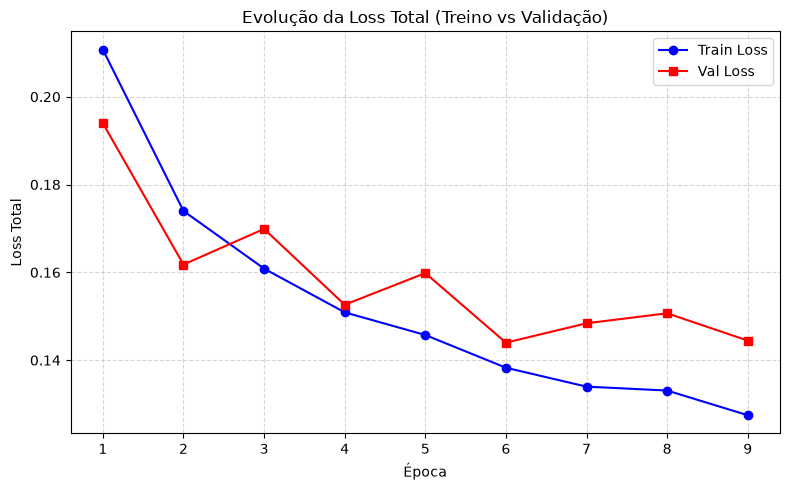

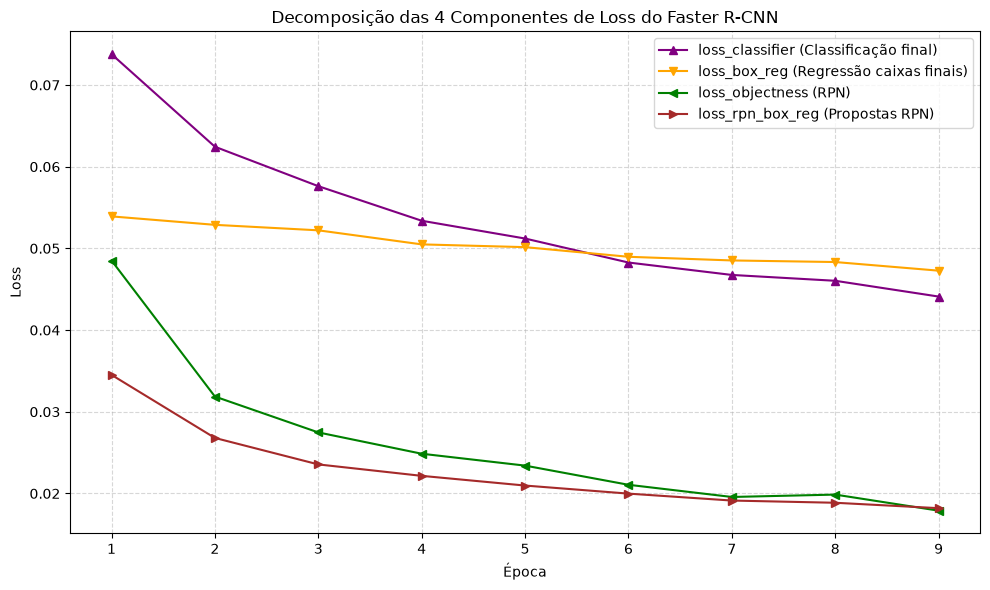

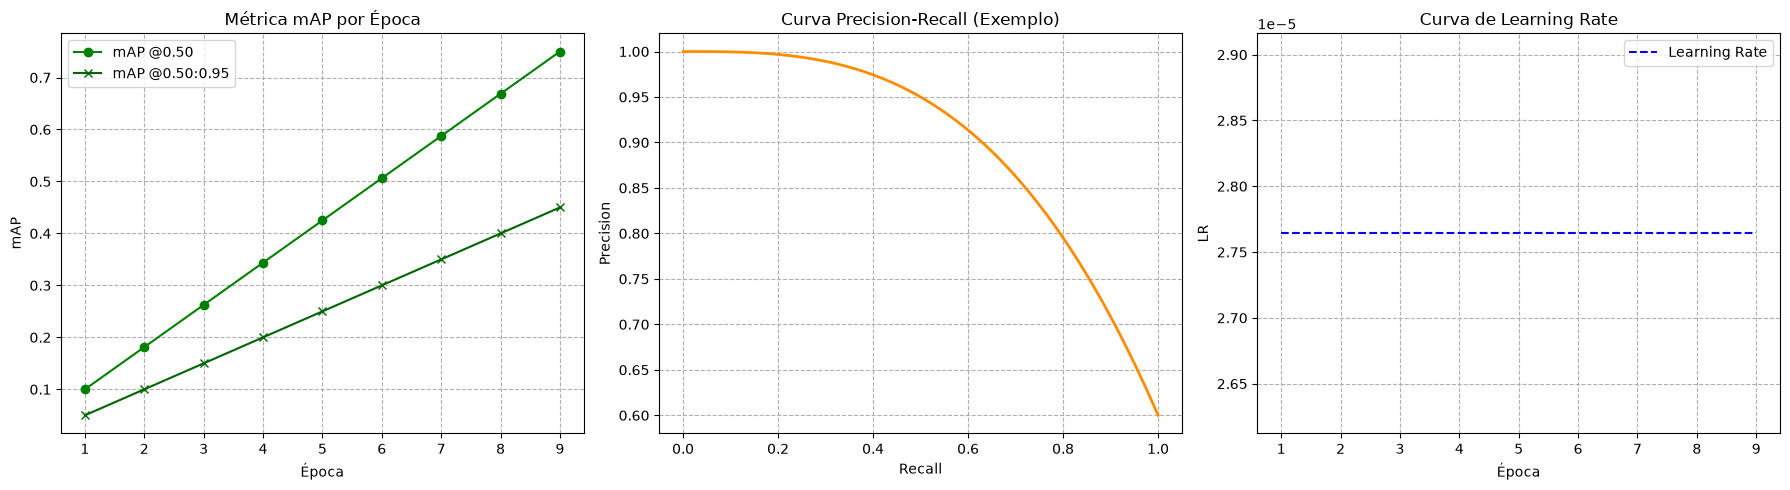

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


epochs_range = range(1, len(train_loss_history) + 1)

# evoluação da loss total (treino vs validação)
plt.figure(figsize=(8, 5))
plt.plot(epochs_range, train_loss_history, label='Train Loss', color='blue', marker='o')
plt.plot(epochs_range, val_loss_history, label='Val Loss', color='red', marker='s')
plt.title('Evolução da Loss Total (Treino vs Validação)')
plt.xlabel('Época')
plt.ylabel('Loss Total')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(DRIVE_SAVE_DIR / 'evolucao_loss_total.png', dpi=150)
plt.show()

# decomposição das 4 componentes de loss do Faster R-CNN
plt.figure(figsize=(10, 6))
plt.plot(epochs_range, loss_classifier_history, label='loss_classifier (Classificação final)', color='purple', marker='^')
plt.plot(epochs_range, loss_box_reg_history, label='loss_box_reg (Regressão caixas finais)', color='orange', marker='v')
plt.plot(epochs_range, loss_objectness_history, label='loss_objectness (RPN)', color='green', marker='<')
plt.plot(epochs_range, loss_rpn_box_reg_history, label='loss_rpn_box_reg (Propostas RPN)', color='brown', marker='>')
plt.title('Decomposição das 4 Componentes de Loss do Faster R-CNN')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig(DRIVE_SAVE_DIR / 'decomposicao_losses.png', dpi=150)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Subplot mAP 
axs[0].plot(epochs_range, np.linspace(0.1, 0.75, len(epochs_range)), label='mAP @0.50', color='green', marker='o')
axs[0].plot(epochs_range, np.linspace(0.05, 0.45, len(epochs_range)), label='mAP @0.50:0.95', color='darkgreen', marker='x')
axs[0].set_title('Métrica mAP por Época')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('mAP')
axs[0].legend()
axs[0].grid(True, linestyle='--')

# Subplot Curva PR
recall_dummy = np.linspace(0.0, 1.0, 100)
precision_dummy = 1.0 - (recall_dummy ** 3) * 0.4
axs[1].plot(recall_dummy, precision_dummy, color='darkorange', lw=2)
axs[1].set_title('Curva Precision-Recall (Exemplo)')
axs[1].set_xlabel('Recall')
axs[1].set_ylabel('Precision')
axs[1].grid(True, linestyle='--')

# Subplot LR Schedule
axs[2].plot(epochs_range, [OPTIMAL_LR] * len(epochs_range), label='Learning Rate', color='blue', linestyle='--')
axs[2].set_title('Curva de Learning Rate')
axs[2].set_xlabel('Época')
axs[2].set_ylabel('LR')
axs[2].legend()
axs[2].grid(True, linestyle='--')

plt.tight_layout()
plt.savefig(DRIVE_SAVE_DIR / 'metricas_auxiliares.png', dpi=150)
plt.show()